# k-Nearest Neighbours: A Detailed Tutorial

**Audience:** students who have seen the supervised-learning setup and basic linear models.

**What you will build:** a complete k-NN workflow, from the distance computation and the
vote to model selection, regression, and a real dataset.

## Learning objectives

By the end of this notebook you will be able to

1. explain what k-NN stores and how it makes a prediction;
2. implement k-NN classification and regression from scratch with NumPy;
3. visualise decision boundaries and explain the role of $k$;
4. show why feature scaling is essential;
5. tune $k$ and the voting rule with cross-validation;
6. compare distance metrics and understand the curse of dimensionality;
7. apply k-NN in a leakage-free scikit-learn pipeline.

## Why k-NN?

k-NN is the "hello world" of non-parametric learning. It has no parameters to fit: it
simply remembers the training set. That makes it a clean testbed for the ideas that recur
throughout the course---distances, hyperparameters, the bias--variance trade-off, and the
difference between memorisation and generalisation.

## 1. Setup

We need only NumPy, matplotlib, and scikit-learn. The random seed is fixed so that the
figures and numbers in the notebook are reproducible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from time import perf_counter

from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_squared_error,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams.update(
    {
        "figure.figsize": (8, 5),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

## 2. The algorithm in one page

Given a query point $\mathbf{x}$, k-NN orders the training points by a distance
$d(\mathbf{x}, \mathbf{x}_i)$ and keeps the $k$ closest ones.

**Classification.** Let $y_{(1)},\ldots,y_{(k)}$ be the labels of those neighbours. The
prediction is the majority label,

$$
\hat{y} = \operatorname{mode}\{y_{(1)},\ldots,y_{(k)}\}.
$$

**Regression.** Average the neighbour targets,

$$
\hat{y} = \frac{1}{k}\sum_{j=1}^{k} y_{(j)}.
$$

**Distance-weighted voting.** Give closer neighbours more influence. For regression the
prediction becomes a weighted average,

$$
\hat{y} = \frac{\sum_{j=1}^{k} w_j\,y_{(j)}}{\sum_{j=1}^{k} w_j},
\qquad w_j = \frac{1}{d(\mathbf{x},\mathbf{x}_{(j)})}.
$$

For classification, sum the weights separately for each class and predict the class with
the largest total weight. If a query exactly matches a training point, that point receives
an effectively infinite weight; the implementation below caps the weight with a small
constant to avoid division by zero.

There is no training phase beyond storing the data, and prediction costs
$O(nd)$ distance computations per query in the brute-force version. The three
hyperparameters that matter most are the distance metric, the number of neighbours $k$,
and the voting weights.

For classification, the estimated class probability is the fraction of the $k$ neighbours
in each class (or the weighted fraction). This is useful for ranking and for inspecting
confidence, even though k-NN probabilities are coarse.

## 3. A dataset to play with

The two-moons dataset is a standard non-linear classification problem: no straight line
separates the classes. We keep a held-out test set that we will touch only at the end of
the model-selection section.

Training points: 375
Test points:     125


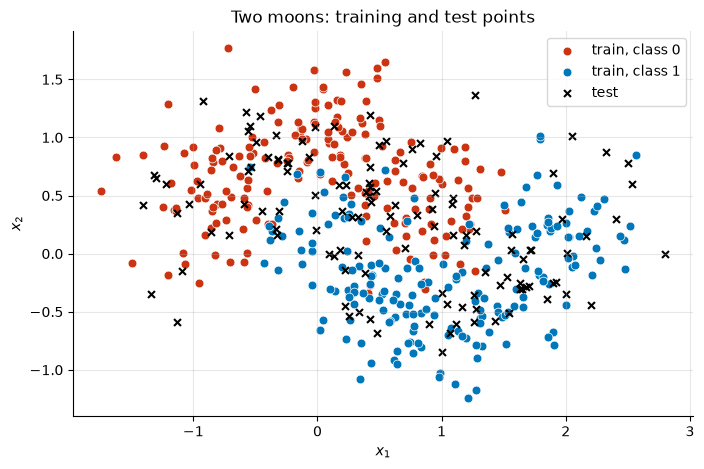

In [24]:
x, y = make_moons(n_samples=500, noise=0.30, random_state=RANDOM_STATE)
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

print(f"Training points: {len(x_train)}")
print(f"Test points:     {len(x_test)}")

fig, ax = plt.subplots()
for label, colour, name in [(0, "#CC3311", "class 0"), (1, "#0077BB", "class 1")]:
    mask = y_train == label
    ax.scatter(
        x_train[mask, 0],
        x_train[mask, 1],
        c=colour,
        s=40,
        edgecolor="white",
        linewidth=0.5,
        label=f"train, {name}",
    )
ax.scatter(x_test[:, 0], x_test[:, 1], marker="x", c="k", s=25, label="test")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Two moons: training and test points")
ax.legend(loc="best")
plt.show()

## 4. k-NN from scratch

### 4.1 Distances

For two vectors $\mathbf{a},\mathbf{b}\in\mathbb{R}^d$:

$$
d_{\text{euclidean}}(\mathbf{a},\mathbf{b})
= \sqrt{\sum_{j=1}^{d}(a_j-b_j)^2},
\qquad
d_{\text{manhattan}}(\mathbf{a},\mathbf{b})
= \sum_{j=1}^{d}|a_j-b_j|.
$$

The cosine distance is $1-\cos(\mathbf{a},\mathbf{b})$, which ignores vector length and
is common for text and embedding vectors.

The function below computes all pairwise distances at once. It uses broadcasting instead
of Python loops, which matters when the training set is large. Broadcasting materialises
an $m\times n\times d$ array, so for very large datasets use scikit-learn's optimised
routines or process the queries in chunks.

In [3]:
def pairwise_distances(A, B, metric="euclidean"):
    '''Distances between every row of A (m x d) and every row of B (n x d).'''
    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)

    if metric == "euclidean":
        return np.sqrt(((A[:, None, :] - B[None, :, :]) ** 2).sum(axis=2))
    if metric == "manhattan":
        return np.abs(A[:, None, :] - B[None, :, :]).sum(axis=2)
    if metric == "cosine":
        A_norm = A / np.clip(np.linalg.norm(A, axis=1, keepdims=True), 1e-12, None)
        B_norm = B / np.clip(np.linalg.norm(B, axis=1, keepdims=True), 1e-12, None)
        return 1.0 - A_norm @ B_norm.T
    raise ValueError(f"Unknown metric: {metric!r}")


# A small sanity check
A = np.array([[0.0, 0.0], [3.0, 4.0]])
B = np.array([[0.0, 0.0], [6.0, 8.0]])
print("Euclidean:\n", pairwise_distances(A, B, "euclidean"))
print("Manhattan:\n", pairwise_distances(A, B, "manhattan"))

Euclidean:
 [[ 0. 10.]
 [ 5.  5.]]
Manhattan:
 [[ 0. 14.]
 [ 7.  7.]]


### 4.2 The classifier

The implementation stores the training data, finds the $k$ smallest distances with
`np.argpartition` (faster than a full sort), and aggregates the labels. A small base
class holds the shared neighbour search so that the regressor can reuse it later.

In [4]:
class _KNNBase:
    '''Shared storage and neighbour search for k-NN estimators.'''

    def __init__(self, n_neighbors=5, weights="uniform", metric="euclidean"):
        self.n_neighbors = n_neighbors
        self.weights = weights
        self.metric = metric

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        if X.ndim != 2:
            raise ValueError("X must be a 2-dimensional array")
        if len(X) != len(y):
            raise ValueError("X and y must have the same number of rows")
        if self.n_neighbors < 1:
            raise ValueError("n_neighbors must be at least 1")
        if self.n_neighbors > len(X):
            raise ValueError("n_neighbors cannot exceed the number of training points")
        if self.weights not in {"uniform", "distance"}:
            raise ValueError("weights must be 'uniform' or 'distance'")
        self.X_fit_ = X
        self.y_fit_ = y
        return self

    def _neighbor_indices(self, X):
        X = np.asarray(X, dtype=float)
        distances = pairwise_distances(X, self.X_fit_, self.metric)
        k = self.n_neighbors
        # Keep the k smallest without sorting the whole row.
        idx = np.argpartition(distances, k - 1, axis=1)[:, :k]
        rows = np.arange(distances.shape[0])[:, None]
        neighbor_distances = distances[rows, idx]
        # Sort the k neighbours so that the output is deterministic.
        order = np.argsort(neighbor_distances, axis=1)
        idx = idx[rows, order]
        neighbor_distances = neighbor_distances[rows, order]
        return idx, neighbor_distances


class KNNClassifier(_KNNBase):
    '''A from-scratch k-nearest-neighbour classifier.'''

    def fit(self, X, y):
        super().fit(X, y)
        self.classes_ = np.unique(self.y_fit_)
        return self

    def predict_proba(self, X):
        idx, neighbor_distances = self._neighbor_indices(X)
        if self.weights == "uniform":
            w = np.ones_like(neighbor_distances)
        else:
            w = 1.0 / np.maximum(neighbor_distances, 1e-12)

        proba = np.zeros((len(idx), len(self.classes_)))
        for j, label in enumerate(self.classes_):
            proba[:, j] = ((self.y_fit_[idx] == label) * w).sum(axis=1)
        return proba / proba.sum(axis=1, keepdims=True)

    def predict(self, X):
        proba = self.predict_proba(X)
        return self.classes_[np.argmax(proba, axis=1)]

### 4.3 Feature scaling first

Euclidean distance sums squared differences, so a feature measured in thousands
dominates one measured in fractions. We standardise each feature to zero mean and unit
variance. Crucially, the scaler is fitted on the **training set only**; the test set is
transformed with those training statistics. This is the simplest example of avoiding
data leakage.

In [5]:
scaler = StandardScaler().fit(x_train)
x_train_s = scaler.transform(x_train)
x_test_s = scaler.transform(x_test)

print("Before scaling:")
print("  mean:", np.round(x_train.mean(axis=0), 3))
print("  std: ", np.round(x_train.std(axis=0), 3))
print("After scaling (training set):")
print("  mean:", np.round(x_train_s.mean(axis=0), 3))
print("  std: ", np.round(x_train_s.std(axis=0), 3))

Before scaling:
  mean: [0.512 0.251]
  std:  [0.903 0.613]
After scaling (training set):
  mean: [-0. -0.]
  std:  [1. 1.]


### 4.4 Check against scikit-learn

If the implementation is correct, its predictions should agree with
`KNeighborsClassifier` on the same scaled data.

In [6]:
scratch = KNNClassifier(n_neighbors=5).fit(x_train_s, y_train)
library = KNeighborsClassifier(n_neighbors=5).fit(x_train_s, y_train)

pred_scratch = scratch.predict(x_test_s)
pred_library = library.predict(x_test_s)

print(f"Scratch accuracy:   {accuracy_score(y_test, pred_scratch):.3f}")
print(f"scikit-learn accuracy: {accuracy_score(y_test, pred_library):.3f}")
print(f"Predictions agree:  {np.mean(pred_scratch == pred_library):.3%}")
print("\nFirst query probabilities (scratch):")
print(scratch.predict_proba(x_test_s[:3]))

Scratch accuracy:   0.904
scikit-learn accuracy: 0.904
Predictions agree:  100.000%

First query probabilities (scratch):
[[0.2 0.8]
 [0.4 0.6]
 [0.6 0.4]]


### 4.5 Looking at one prediction

Let us inspect the neighbours of a single test point. This is the best way to build
intuition for what k-NN is actually doing.

In [7]:
query_id = 0
query = x_test_s[query_id]
distances = np.linalg.norm(x_train_s - query, axis=1)
nearest = np.argsort(distances)[:10]

print(f"Query features (standardised): {np.round(query, 3)}")
print(f"True test label: {y_test[query_id]}\n")
print(" rank  distance  label")
for rank, i in enumerate(nearest, start=1):
    print(f"{rank:5d}  {distances[i]:8.3f}  {y_train[i]}")

print("\n5-NN class probabilities:", scratch.predict_proba([query])[0])

Query features (standardised): [-0.206 -0.424]
True test label: 1

 rank  distance  label
    1     0.116  1
    2     0.161  1
    3     0.181  1
    4     0.205  0
    5     0.220  1
    6     0.226  1
    7     0.228  1
    8     0.310  1
    9     0.314  1
   10     0.319  1

5-NN class probabilities: [0.2 0.8]


## 5. Decision boundaries

A decision boundary is the set of points where the predicted class changes. Small $k$
produces a jagged boundary that follows individual points (low bias, high variance).
Large $k$ produces a smooth boundary that may ignore genuine structure (high bias, low
variance). The plots below use scikit-learn for speed; the model is the same one we
implemented above.

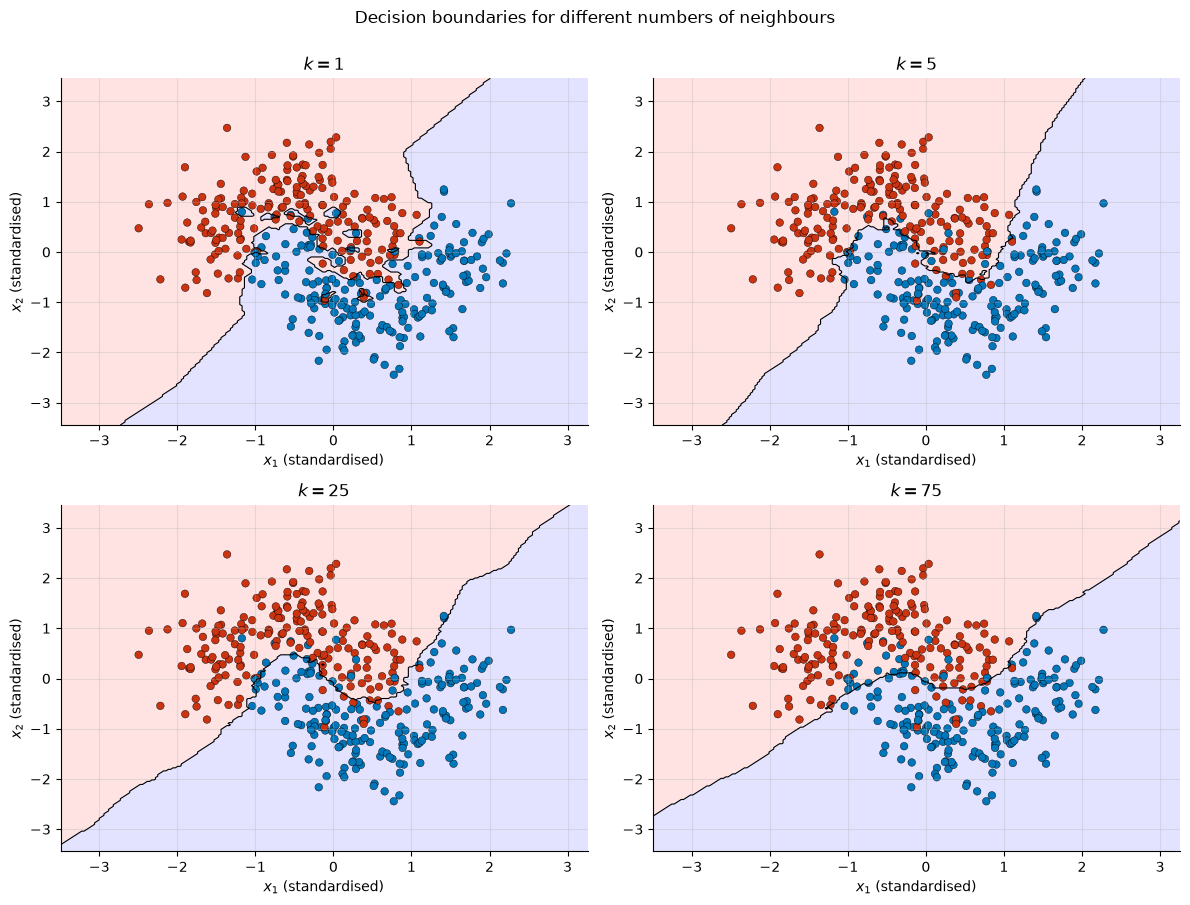

In [8]:
def plot_decision_boundary(ax, model, X, y, title, resolution=0.03):
    '''Draw the classifier's regions and the training points on ax.'''
    x_min, x_max = X[:, 0].min() - 1.0, X[:, 0].max() + 1.0
    y_min, y_max = X[:, 1].min() - 1.0, X[:, 1].max() + 1.0
    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, resolution),
        np.arange(y_min, y_max, resolution),
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)

    ax.contourf(
        xx,
        yy,
        zz,
        levels=[-0.5, 0.5, 1.5],
        colors=["#FFDDDD", "#DDDDFF"],
        alpha=0.8,
    )
    ax.contour(xx, yy, zz, levels=[0.5], colors="k", linewidths=0.8)
    ax.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        cmap=ListedColormap(["#CC3311", "#0077BB"]),
        edgecolor="k",
        linewidth=0.3,
        s=30,
    )
    ax.set_title(title)
    ax.set_xlabel("$x_1$ (standardised)")
    ax.set_ylabel("$x_2$ (standardised)")


fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, k in zip(axes.ravel(), [1, 5, 25, 75]):
    model = KNeighborsClassifier(n_neighbors=k).fit(x_train_s, y_train)
    plot_decision_boundary(ax, model, x_train_s, y_train, f"$k = {k}$")
fig.suptitle("Decision boundaries for different numbers of neighbours", y=1.00)
fig.tight_layout()
plt.show()

Read the panels from left to right and top to bottom:

- $k=1$: every training point is its own island; the boundary is highly irregular.
- $k=5$: a reasonable compromise for this dataset.
- $k=25$: smoother, but small pockets are starting to be missed.
- $k=75$: over-smoothing; the classifier is close to a global rule and underfits.

The test set would let us choose among these, but choosing $k$ on the test set would
leak information. Section 7 uses cross-validation on the training set instead.

## 6. Why feature scaling is essential

Consider a dataset with two informative features and one pure-noise feature measured on a
much larger scale. Without scaling, the noise feature dominates every distance and the
neighbours become essentially random. With scaling, each feature contributes comparably.

In [9]:
rng = np.random.default_rng(RANDOM_STATE)
n = 500

x1 = rng.normal(0, 1, n)
x2 = x1 + rng.normal(0, 0.5, n)
x3 = rng.normal(0, 1000, n)  # pure noise, huge scale
X_scale = np.column_stack([x1, x2, x3])

logits = 1.5 * x1 + 1.0 * x2
y_scale = (logits + rng.normal(0, 1.0, n) > 0).astype(int)

print("Standard deviations per feature:", np.round(X_scale.std(axis=0), 1))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = {
    "no scaling": Pipeline([("knn", KNeighborsClassifier(n_neighbors=5))]),
    "standardised": Pipeline(
        [("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=5))]
    ),
}

for name, model in models.items():
    scores = cross_val_score(model, X_scale, y_scale, cv=cv, scoring="accuracy")
    print(f"{name:>14s}: {scores.mean():.3f} +/- {scores.std():.3f}")

Standard deviations per feature: [1.0000e+00 1.1000e+00 1.0203e+03]
    no scaling: 0.532 +/- 0.033
  standardised: 0.826 +/- 0.030


The unscaled model performs close to chance: the squared difference in the noise feature
is roughly $10^6$ times larger than the squared differences in the informative features.
Standardisation restores a sensible accuracy.

> **Rule of thumb.** Put the scaler inside a `Pipeline`, not outside the
> cross-validation loop. Fitting the scaler on all data before splitting leaks
> information from the validation folds.

## 7. Choosing $k$ with cross-validation

We evaluate odd values of $k$ from 1 to 39 using stratified 5-fold cross-validation on
the training set. Odd values avoid a tied majority vote in binary classification. We
track both training accuracy and cross-validation accuracy to see the bias--variance
trade-off directly.

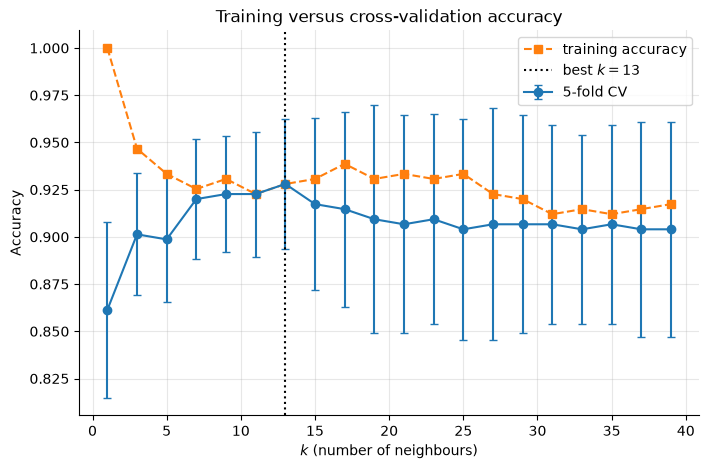

Best k from CV: 13
Best CV accuracy: 0.928


In [10]:
ks = np.arange(1, 40, 2)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

train_acc = []
cv_means = []
cv_stds = []

for k in ks:
    model = Pipeline(
        [("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=int(k)))]
    )
    scores = cross_val_score(model, x_train, y_train, cv=cv, scoring="accuracy")
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())
    train_acc.append(model.fit(x_train, y_train).score(x_train, y_train))

cv_means = np.array(cv_means)
cv_stds = np.array(cv_stds)
best_k = int(ks[np.argmax(cv_means)])

fig, ax = plt.subplots()
ax.errorbar(ks, cv_means, yerr=cv_stds, marker="o", capsize=3, label="5-fold CV")
ax.plot(ks, train_acc, marker="s", linestyle="--", label="training accuracy")
ax.axvline(best_k, color="k", linestyle=":", label=f"best $k = {best_k}$")
ax.set_xlabel("$k$ (number of neighbours)")
ax.set_ylabel("Accuracy")
ax.set_title("Training versus cross-validation accuracy")
ax.legend()
plt.show()

print(f"Best k from CV: {best_k}")
print(f"Best CV accuracy: {cv_means.max():.3f}")

In [25]:
final_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=best_k)),
    ]
).fit(x_train, y_train)

test_accuracy = final_pipeline.score(x_test, y_test)
print(f"Test accuracy with k = {best_k}: {test_accuracy:.3f}")

Test accuracy with k = 13: 0.912


The training curve is decreasing in $k$: with $k=1$ the training error is zero because
every point is its own nearest neighbour. The cross-validation curve falls at both ends.
Small $k$ has low bias but high variance; large $k$ has low variance but high bias. The
best value is where the two effects balance, and it is a property of the dataset, not a
universal constant.

## 8. Uniform versus distance-weighted voting

Distance weighting often helps when the neighbourhood contains points at very different
distances. The next plot compares both rules across $k$, with standardisation performed
inside every cross-validation fold.

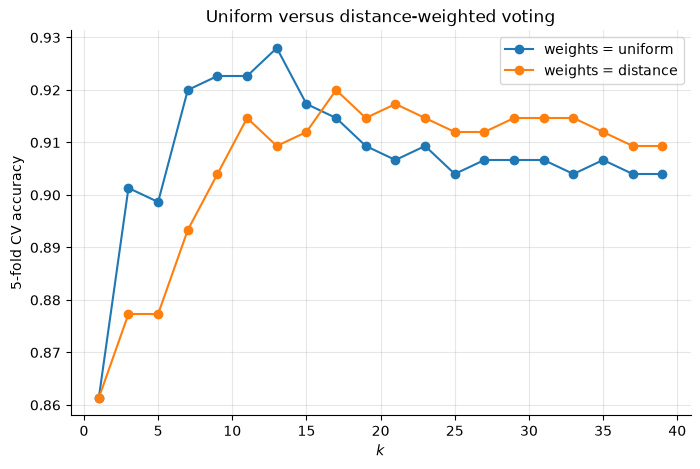

  uniform: best k = 13, CV accuracy = 0.928
 distance: best k = 17, CV accuracy = 0.920


In [12]:
cv_scores = {}
for weights in ["uniform", "distance"]:
    cv_scores[weights] = [
        cross_val_score(
            Pipeline(
                [
                    ("scaler", StandardScaler()),
                    (
                        "knn",
                        KNeighborsClassifier(n_neighbors=int(k), weights=weights),
                    ),
                ]
            ),
            x_train,
            y_train,
            cv=cv,
            scoring="accuracy",
        ).mean()
        for k in ks
    ]

fig, ax = plt.subplots()
for weights, scores in cv_scores.items():
    ax.plot(ks, scores, marker="o", label=f"weights = {weights}")
ax.set_xlabel("$k$")
ax.set_ylabel("5-fold CV accuracy")
ax.set_title("Uniform versus distance-weighted voting")
ax.legend()
plt.show()

for weights, scores in cv_scores.items():
    j = int(np.argmax(scores))
    print(f"{weights:>9s}: best k = {ks[j]:2d}, CV accuracy = {scores[j]:.3f}")

## 9. Distance metrics

The choice of metric encodes what "similar" means. Euclidean distance is the default for
standardised tabular data. Manhattan distance is more robust to outliers because it does
not square differences. Cosine distance ignores magnitude and is standard for text and
embedding vectors.

We compare all three on the two-moons data, again with standardisation inside every
cross-validation fold. Because the data are low-dimensional, the differences are modest;
on other problems they can be large.

    metric  best k  CV accuracy
 euclidean      13        0.928
 manhattan       9        0.925
    cosine      35        0.845


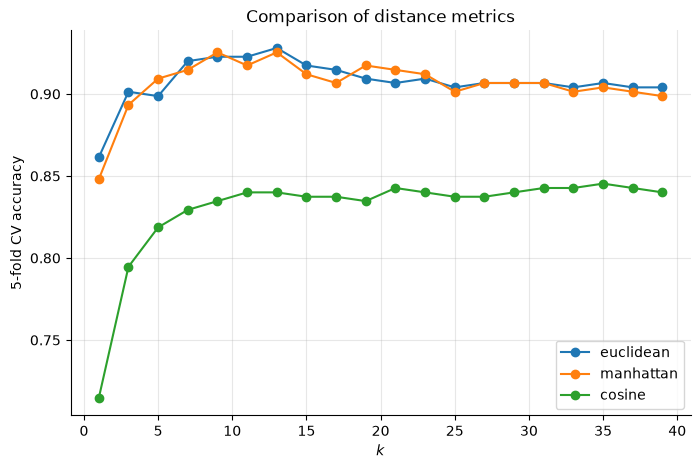

In [13]:
metrics = ["euclidean", "manhattan", "cosine"]
metric_scores = {}

for metric in metrics:
    metric_scores[metric] = [
        cross_val_score(
            Pipeline(
                [
                    ("scaler", StandardScaler()),
                    (
                        "knn",
                        KNeighborsClassifier(n_neighbors=int(k), metric=metric),
                    ),
                ]
            ),
            x_train,
            y_train,
            cv=cv,
            scoring="accuracy",
        ).mean()
        for k in ks
    ]

print(f"{'metric':>10s}  {'best k':>6s}  {'CV accuracy':>11s}")
for metric, scores in metric_scores.items():
    j = int(np.argmax(scores))
    print(f"{metric:>10s}  {ks[j]:6d}  {scores[j]:11.3f}")

fig, ax = plt.subplots()
for metric, scores in metric_scores.items():
    ax.plot(ks, scores, marker="o", label=metric)
ax.set_xlabel("$k$")
ax.set_ylabel("5-fold CV accuracy")
ax.set_title("Comparison of distance metrics")
ax.legend()
plt.show()

## 10. k-NN for regression

For regression, replace the majority vote with an average. The regressor reuses the base
class from Section 4.2. We generate a noisy sine wave; $k=1$ interpolates the training
points, while large $k$ flattens the curve.

In [14]:
class KNNRegressor(_KNNBase):
    '''A from-scratch k-nearest-neighbour regressor.'''

    def predict(self, X):
        idx, neighbor_distances = self._neighbor_indices(X)
        if self.weights == "uniform":
            w = np.ones_like(neighbor_distances)
        else:
            w = 1.0 / np.maximum(neighbor_distances, 1e-12)
        return (self.y_fit_[idx] * w).sum(axis=1) / w.sum(axis=1)

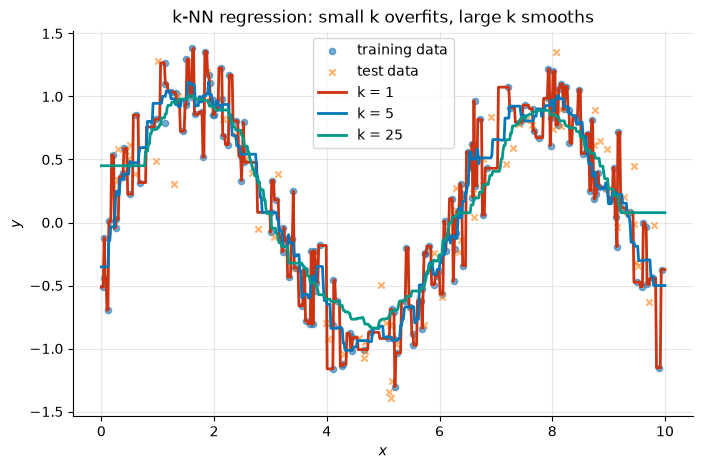

In [15]:
rng = np.random.default_rng(7)
X_reg = np.sort(rng.uniform(0, 10, 250))[:, None]
y_reg = np.sin(X_reg).ravel() + 0.25 * rng.normal(size=250)

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.3, random_state=RANDOM_STATE
)
grid = np.linspace(0, 10, 600)[:, None]

fig, ax = plt.subplots()
ax.scatter(Xr_train, yr_train, s=20, alpha=0.6, label="training data")
ax.scatter(Xr_test, yr_test, s=20, alpha=0.6, marker="x", label="test data")
for k, colour in [(1, "#CC3311"), (5, "#0077BB"), (25, "#009988")]:
    model = KNNRegressor(n_neighbors=k).fit(Xr_train, yr_train)
    ax.plot(grid, model.predict(grid), color=colour, linewidth=2, label=f"k = {k}")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("k-NN regression: small k overfits, large k smooths")
ax.legend()
plt.show()

### 10.1 Regression error versus $k$

We compare our implementation with scikit-learn and compute the root mean squared error
(RMSE) on the test set. The two implementations should produce essentially identical
predictions for uniform weights.

In [16]:
print(f"{'k':>3s}  {'scratch RMSE':>13s}  {'sklearn RMSE':>13s}  {'max |difference|':>17s}")
for k in [1, 3, 5, 10, 20, 50]:
    ours = KNNRegressor(n_neighbors=k).fit(Xr_train, yr_train)
    theirs = KNeighborsRegressor(n_neighbors=k).fit(Xr_train, yr_train)
    pred_ours = ours.predict(Xr_test)
    pred_theirs = theirs.predict(Xr_test)
    rmse_ours = np.sqrt(mean_squared_error(yr_test, pred_ours))
    rmse_theirs = np.sqrt(mean_squared_error(yr_test, pred_theirs))
    gap = np.max(np.abs(pred_ours - pred_theirs))
    print(f"{k:3d}  {rmse_ours:13.3f}  {rmse_theirs:13.3f}  {gap:17.2e}")

  k   scratch RMSE   sklearn RMSE   max |difference|
  1          0.350          0.350           0.00e+00
  3          0.293          0.293           0.00e+00
  5          0.262          0.262           0.00e+00
 10          0.260          0.260           0.00e+00
 20          0.267          0.267           0.00e+00
 50          0.392          0.392           0.00e+00


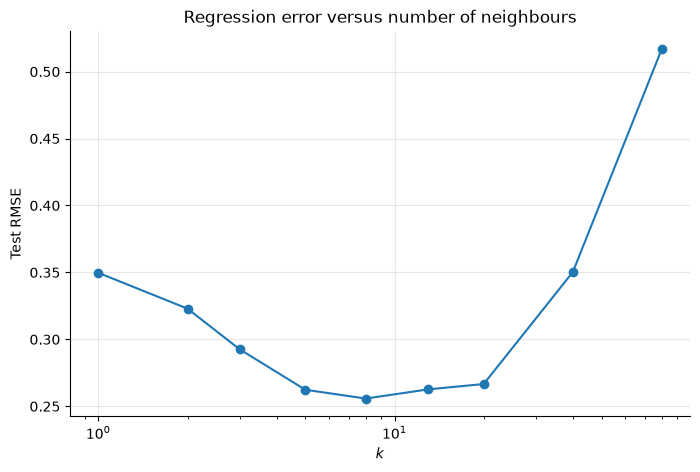

Best k on this test curve: 8


In [17]:
ks_reg = [1, 2, 3, 5, 8, 13, 20, 40, 80]
rmse_curve = []
for k in ks_reg:
    model = KNNRegressor(n_neighbors=k).fit(Xr_train, yr_train)
    rmse_curve.append(np.sqrt(mean_squared_error(yr_test, model.predict(Xr_test))))

fig, ax = plt.subplots()
ax.plot(ks_reg, rmse_curve, marker="o")
ax.set_xscale("log")
ax.set_xlabel("$k$")
ax.set_ylabel("Test RMSE")
ax.set_title("Regression error versus number of neighbours")
plt.show()

best_k_reg = ks_reg[int(np.argmin(rmse_curve))]
print(f"Best k on this test curve: {best_k_reg}")

In practice $k$ must again be chosen by cross-validation, not by looking at the test
curve. The curve is shown only to illustrate the bias--variance pattern.

## 11. The curse of dimensionality

k-NN relies on the idea that nearby points have similar targets. In high dimensions that
idea weakens: random points become almost equidistant. A useful diagnostic is the ratio
of the nearest to the farthest distance. When the ratio approaches one, "nearest" is no
longer meaningfully nearer than "farthest".

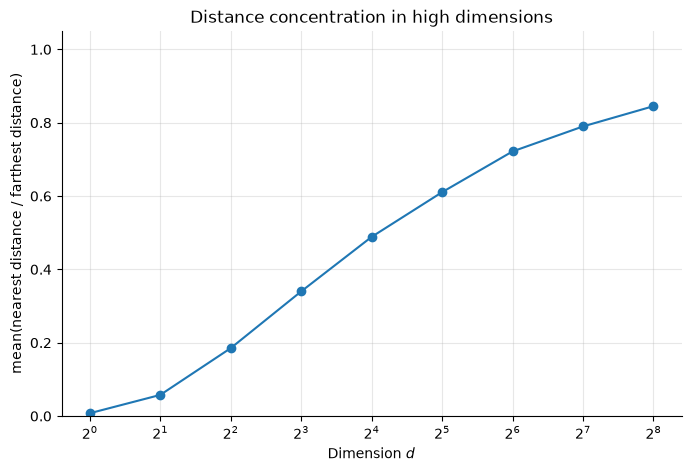

d =   1: ratio = 0.008
d =   2: ratio = 0.058
d =   4: ratio = 0.185
d =   8: ratio = 0.340
d =  16: ratio = 0.489
d =  32: ratio = 0.611
d =  64: ratio = 0.722
d = 128: ratio = 0.790
d = 256: ratio = 0.845


In [18]:
rng = np.random.default_rng(RANDOM_STATE)
dims = [1, 2, 4, 8, 16, 32, 64, 128, 256]
n_points = 80
ratios = []

for d in dims:
    A = rng.random((n_points, d))
    B = rng.random((n_points, d))
    distances = np.linalg.norm(A[:, None, :] - B[None, :, :], axis=2)
    ratios.append(np.mean(distances.min(axis=1) / distances.max(axis=1)))

fig, ax = plt.subplots()
ax.plot(dims, ratios, marker="o")
ax.set_xscale("log", base=2)
ax.set_xlabel("Dimension $d$")
ax.set_ylabel("mean(nearest distance / farthest distance)")
ax.set_title("Distance concentration in high dimensions")
ax.set_ylim(0, 1.05)
plt.show()

for d, ratio in zip(dims, ratios):
    print(f"d = {d:3d}: ratio = {ratio:.3f}")

Mitigations include

- reducing dimensionality before applying k-NN (PCA, feature selection);
- using a metric suited to the data (cosine for normalised embeddings);
- learning a metric from labelled data (metric learning);
- using approximate nearest-neighbour indexes designed for high dimensions.

Even when distances concentrate, k-NN can work well if the data lie near a
lower-dimensional manifold and the metric respects its geometry.

## 12. Computational cost and spatial indexes

Brute-force prediction compares the query with every training point: $O(nd)$ work per
query. For low-dimensional data, a tree structure such as a k-d tree or a ball tree can
avoid most comparisons. In high dimensions the curse of dimensionality defeats these
indexes and brute force is often competitive.

The benchmark below times prediction only; fitting a tree has its own cost. Timings are
machine-dependent, so read the orders of magnitude rather than the exact numbers. With a
small training set the Python-level overhead of traversing a tree can dominate, so we use
ten thousand training points to expose the crossover.

In [19]:
def time_prediction(algorithm, d, n_samples=10000, n_queries=500, k=5, repeats=2):
    rng = np.random.default_rng(0)
    Xb = rng.normal(size=(n_samples, d))
    yb = (Xb[:, 0] > 0).astype(int)
    queries = rng.normal(size=(n_queries, d))

    model = KNeighborsClassifier(n_neighbors=k, algorithm=algorithm).fit(Xb, yb)
    model.predict(queries[:5])  # warm-up

    timings = []
    for _ in range(repeats):
        start = perf_counter()
        model.predict(queries)
        timings.append(perf_counter() - start)
    return min(timings) * 1000  # milliseconds


algorithms = ["brute", "kd_tree", "ball_tree"]
print(f"{'d':>4s}  " + "  ".join(f"{a:>10s}" for a in algorithms))
for d in [2, 10, 50, 100]:
    row = [time_prediction(a, d) for a in algorithms]
    print(f"{d:4d}  " + "  ".join(f"{t:8.2f}ms" for t in row))

   d       brute     kd_tree   ball_tree
   2      2.69ms      1.08ms      2.74ms
  10      2.66ms     14.97ms     16.95ms
  50      2.75ms     96.18ms     61.03ms
 100      4.03ms    228.40ms    155.98ms


At $d=2$ the k-d tree is faster because it prunes most of the training points. As the
dimension grows, pruning becomes ineffective: by $d=50$ the tree has to inspect so many
boxes that brute force wins. This is the practical face of the curse of dimensionality.

## 13. A real dataset: breast cancer diagnosis

We now apply the complete workflow to the breast-cancer dataset: 569 samples, 30
features, and a binary target. The pipeline standardises the features and tunes both $k$
and the voting rule with 5-fold cross-validation. Everything is inside the pipeline, so
no information from the validation folds leaks into the scaler.

In [20]:
data = load_breast_cancer()
Xc, yc = data.data, data.target
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.20, stratify=yc, random_state=RANDOM_STATE
)

print(f"Training samples: {len(Xc_train)}")
print(f"Test samples:     {len(Xc_test)}")
print(f"Features:         {Xc.shape[1]}")
print(f"Classes:          {list(data.target_names)}")

Training samples: 455
Test samples:     114
Features:         30
Classes:          [np.str_('malignant'), np.str_('benign')]


In [21]:
cv_real = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

unscaled_score = cross_val_score(
    KNeighborsClassifier(n_neighbors=5), Xc_train, yc_train, cv=cv_real, scoring="accuracy"
).mean()

scaled_score = cross_val_score(
    Pipeline(
        [("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=5))]
    ),
    Xc_train,
    yc_train,
    cv=cv_real,
    scoring="accuracy",
).mean()

print(f"5-NN, no scaling:   {unscaled_score:.3f}")
print(f"5-NN, standardised: {scaled_score:.3f}")

5-NN, no scaling:   0.941
5-NN, standardised: 0.963


In [22]:
pipe = Pipeline(
    [("scaler", StandardScaler()), ("knn", KNeighborsClassifier())]
)
param_grid = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31],
    "knn__weights": ["uniform", "distance"],
}

search = GridSearchCV(pipe, param_grid, cv=cv_real, scoring="accuracy")
search.fit(Xc_train, yc_train)

print(f"Best parameters: {search.best_params_}")
print(f"Best CV accuracy: {search.best_score_:.3f}")

test_score = search.score(Xc_test, yc_test)
print(f"Test accuracy:    {test_score:.3f}")

Best parameters: {'knn__n_neighbors': 9, 'knn__weights': 'uniform'}
Best CV accuracy: 0.965
Test accuracy:    0.974


              precision    recall  f1-score   support

   malignant       1.00      0.93      0.96        42
      benign       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



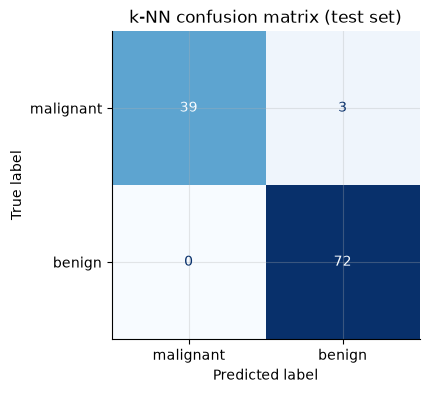

In [23]:
y_pred = search.predict(Xc_test)

print(classification_report(yc_test, y_pred, target_names=data.target_names))

cm = confusion_matrix(yc_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=data.target_names
).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("k-NN confusion matrix (test set)")
plt.show()

The confusion matrix shows where the errors occur. On this dataset the classes are
reasonably balanced, but in a screening application a false negative (a missed malignant
tumour) is usually much more costly than a false positive. Accuracy alone would hide that
asymmetry; report per-class precision and recall, and choose the decision threshold or
the model with the costs in mind.

## 14. Practical checklist

| Issue | Recommendation |
|---|---|
| Features on different scales | Standardise (or normalise) inside a `Pipeline`. |
| Choosing $k$ | Use stratified cross-validation; odd $k$ avoids ties in binary problems. |
| Distance metric | Euclidean for standardised tabular data, Manhattan for robustness, cosine for text/embeddings. |
| Distance weighting | Try `weights="distance"`; it can help when neighbour distances vary a lot. |
| Class imbalance | k-NN has no `class_weight`; use resampling, custom weights, or cost-sensitive decisions, and report per-class metrics. |
| High dimensions | Reduce dimension, use a suitable metric, or use approximate nearest-neighbour methods. |
| Prediction cost | Brute force is $O(nd)$ per query; use a k-d tree/ball tree for low $d$, approximate indexes for large data. |
| Missing values | Impute before k-NN; `KNNImputer` is itself a k-NN method. |
| Ties | Use odd $k$ for binary classification and define a deterministic tie-break. |
| Leakage | Fit scalers and any preprocessing inside cross-validation, never on the full dataset. |

### Related variants

- **Radius neighbours:** return all points within a fixed radius rather than a fixed count.
- **KNN imputation:** fill a missing feature from the average of its nearest complete rows.
- **Condensed / edited nearest neighbours:** prune training points to reduce storage and
  smooth the boundary.
- **Approximate nearest neighbours:** FAISS, Annoy, and HNSW trade a little accuracy for
  large speed gains on big datasets.
- **Metric learning:** learn a distance from labelled pairs (for example neighbourhood
  components analysis) instead of fixing Euclidean distance.

## 15. Exercises

1. **Minkowski distance.** Implement
   $d_p(\mathbf{a},\mathbf{b}) = \left(\sum_j |a_j-b_j|^p\right)^{1/p}$
   and verify that $p=1$ gives Manhattan and $p=2$ gives Euclidean distance.
2. **Gaussian weights.** Replace $w_j=1/d_j$ with
   $w_j=\exp(-d_j^2/(2\sigma^2))$ and study how $\sigma$ changes the decision boundary.
3. **Text classification.** Represent short documents with TF-IDF features and compare
   Euclidean and cosine distance. Explain why cosine is usually preferred.
4. **Imputation.** Implement a simple KNN imputer for one missing feature and compare it
   with mean imputation on a dataset with artificially removed values.
5. **Effect of $k=N$.** Show that when $k$ equals the number of training points, the
   classifier predicts the majority class for every query. Relate this to the bias--variance
   trade-off.
6. **Cost-sensitive evaluation.** On the breast-cancer data, compute the confusion matrix
   for several values of $k$ and discuss which errors matter most in a screening context.
7. **Cross-validation curve.** Reproduce the $k$ selection curve for the breast-cancer
   dataset and compare the chosen $k$ with the one chosen for the two-moons data.

## Further reading

- T. Cover and P. Hart, "Nearest Neighbor Pattern Classification", *IEEE Transactions on
  Information Theory*, 1967.
- T. Hastie, R. Tibshirani, and J. Friedman, *The Elements of Statistical Learning*,
  Chapter 2 (overview) and Chapter 13 (prototype methods and nearest neighbours).
- scikit-learn user guide: *Nearest Neighbors*.
- L. van der Maaten and G. Hinton, "Visualizing Data using t-SNE", *JMLR*, 2008, for the
  high-dimensional geometry discussed in Section 11.